# Week 6 AI Lab: Informed Search Techniques in Python

**Completed graded submission:** Tasks 1-5 and the required Streamlit GUI.

Tasks 6-7 are excluded because the task document explicitly labels them **Ungraded Tasks**. All required graphs below use NetworkX and highlight the solution path. This notebook has been executed so that outputs remain visible for submission.

In [1]:
import heapq
import math
from itertools import count

import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd

pd.set_option("display.max_colwidth", None)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})


def reconstruct_path(came_from, current):
    path = [current]
    while came_from[current] is not None:
        current = came_from[current]
        path.append(current)
    return list(reversed(path))


def calculate_path_cost(graph, path):
    return sum(graph[a][b] for a, b in zip(path, path[1:]))


def draw_weighted_graph(graph_data, positions, solution_path, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 6.5))

    graph = nx.DiGraph()
    graph.add_nodes_from(graph_data)
    for node, neighbors in graph_data.items():
        for neighbor, weight in neighbors.items():
            graph.add_edge(node, neighbor, weight=weight)

    path_edges = list(zip(solution_path, solution_path[1:]))
    other_edges = [edge for edge in graph.edges if edge not in path_edges]

    nx.draw_networkx_nodes(
        graph, positions, node_color="#D9EAF7", edgecolors="#1F4E78",
        node_size=2200, linewidths=1.5, ax=ax
    )
    nx.draw_networkx_nodes(
        graph, positions, nodelist=solution_path, node_color="#FFD966",
        edgecolors="#B45F06", node_size=2300, linewidths=2, ax=ax
    )
    nx.draw_networkx_labels(
        graph, positions,
        labels={node: node.replace("_", "\n") for node in graph.nodes},
        font_size=8, font_weight="bold", ax=ax
    )
    nx.draw_networkx_edges(
        graph, positions, edgelist=other_edges, edge_color="#7F8C8D",
        width=1.8, arrows=True, arrowsize=18, ax=ax
    )
    nx.draw_networkx_edges(
        graph, positions, edgelist=path_edges, edge_color="#D62728",
        width=4, arrows=True, arrowsize=22, ax=ax
    )
    nx.draw_networkx_edge_labels(
        graph, positions,
        edge_labels=nx.get_edge_attributes(graph, "weight"),
        font_size=8, label_pos=0.55, ax=ax
    )
    ax.set_title(title)
    ax.axis("off")
    return graph


print("Imports and shared helper functions loaded successfully.")

Imports and shared helper functions loaded successfully.


## Task 1: Designing a Heuristic for a Warehouse Robot

The heuristic is the Euclidean distance from a location to `Packing_Station`:

\[
h(n)=\sqrt{(x_{goal}-x_n)^2+(y_{goal}-y_n)^2}
\]

Heuristic values


,Location,h(n) to Packing Station
0,Receiving_Area,9.22
1,Storage_A,7.07
2,Storage_B,6.32
3,Sorting_Area,5.00
4,Inspection_Area,2.24
5,Packing_Station,0.00


Minimum-cost path: Receiving_Area -> Storage_A -> Sorting_Area -> Packing_Station
Total cost: 9.40

Consistency check: h(n) <= cost(n,m) + h(m)


,Edge,h(n),"cost(n,m) + h(m)",Condition Holds
0,Receiving_Area -> Storage_A,9.220,9.271,True
1,Receiving_Area -> Storage_B,9.220,10.425,True
2,Storage_A -> Sorting_Area,7.071,7.200,True
3,Storage_B -> Inspection_Area,6.325,7.236,True
4,Storage_B -> Sorting_Area,6.325,11.000,True
5,Sorting_Area -> Inspection_Area,5.000,5.436,True
6,Sorting_Area -> Packing_Station,5.000,5.000,True
7,Inspection_Area -> Packing_Station,2.236,2.200,False


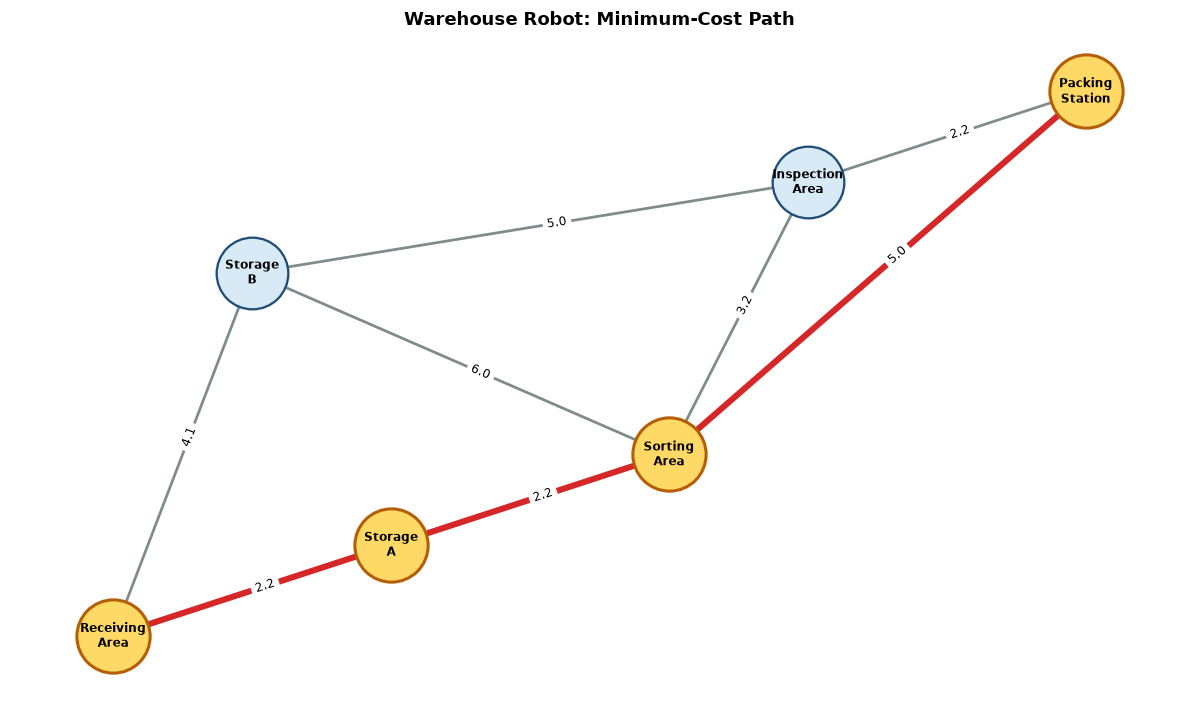

In [2]:
warehouse_locations = {
    "Receiving_Area": (0, 0),
    "Storage_A": (2, 1),
    "Storage_B": (1, 4),
    "Sorting_Area": (4, 2),
    "Inspection_Area": (5, 5),
    "Packing_Station": (7, 6),
}

warehouse_graph = {
    "Receiving_Area": {"Storage_A": 2.2, "Storage_B": 4.1},
    "Storage_A": {"Sorting_Area": 2.2},
    "Storage_B": {"Inspection_Area": 5.0, "Sorting_Area": 6.0},
    "Sorting_Area": {"Inspection_Area": 3.2, "Packing_Station": 5.0},
    "Inspection_Area": {"Packing_Station": 2.2},
    "Packing_Station": {},
}


def warehouse_heuristic(current, goal="Packing_Station"):
    x1, y1 = warehouse_locations[current]
    x2, y2 = warehouse_locations[goal]
    return math.hypot(x2 - x1, y2 - y1)


heuristic_table = pd.DataFrame(
    {
        "Location": list(warehouse_locations),
        "h(n) to Packing Station": [
            round(warehouse_heuristic(node), 2) for node in warehouse_locations
        ],
    }
)
print("Heuristic values")
display(heuristic_table)

warehouse_nx = nx.DiGraph()
for node, neighbors in warehouse_graph.items():
    warehouse_nx.add_node(node)
    for neighbor, weight in neighbors.items():
        warehouse_nx.add_edge(node, neighbor, weight=weight)

warehouse_path = nx.shortest_path(
    warehouse_nx,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight",
)
warehouse_cost = nx.shortest_path_length(
    warehouse_nx,
    source="Receiving_Area",
    target="Packing_Station",
    weight="weight",
)
print("Minimum-cost path:", " -> ".join(warehouse_path))
print(f"Total cost: {warehouse_cost:.2f}")

consistency_rows = []
for node, neighbors in warehouse_graph.items():
    for neighbor, edge_cost in neighbors.items():
        left = warehouse_heuristic(node)
        right = edge_cost + warehouse_heuristic(neighbor)
        consistency_rows.append(
            {
                "Edge": f"{node} -> {neighbor}",
                "h(n)": round(left, 3),
                "cost(n,m) + h(m)": round(right, 3),
                "Condition Holds": left <= right + 1e-12,
            }
        )

print("\nConsistency check: h(n) <= cost(n,m) + h(m)")
display(pd.DataFrame(consistency_rows))

plt.figure(figsize=(11, 6.5))
draw_weighted_graph(
    warehouse_graph,
    warehouse_locations,
    warehouse_path,
    "Warehouse Robot: Minimum-Cost Path",
    plt.gca(),
)
plt.tight_layout()
plt.show()

**Observation.** Euclidean distance is appropriate because the nodes have 2D coordinates and straight-line distance is a natural lower-bound estimate of remaining movement. The check shows one very small violation on `Inspection_Area -> Packing_Station`: the exact Euclidean distance is about 2.236 while the supplied edge cost is rounded to 2.2. Therefore, with the numbers exactly as given, the heuristic is not strictly consistent on that single edge; using an edge cost of at least 2.236 (or rounding the heuristic down conservatively) would restore consistency.

## Task 2: Greedy Best-First Search for Airport Baggage Handling

GBFS orders the frontier only by `h(n)`, so it follows the node that appears closest to the departure gate even when that produces a higher-cost route.

GBFS
Expansion order: Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate
Solution path: Baggage_Area -> Checkpoint -> Terminal_Hall -> Departure_Gate
Total path cost: 12.30


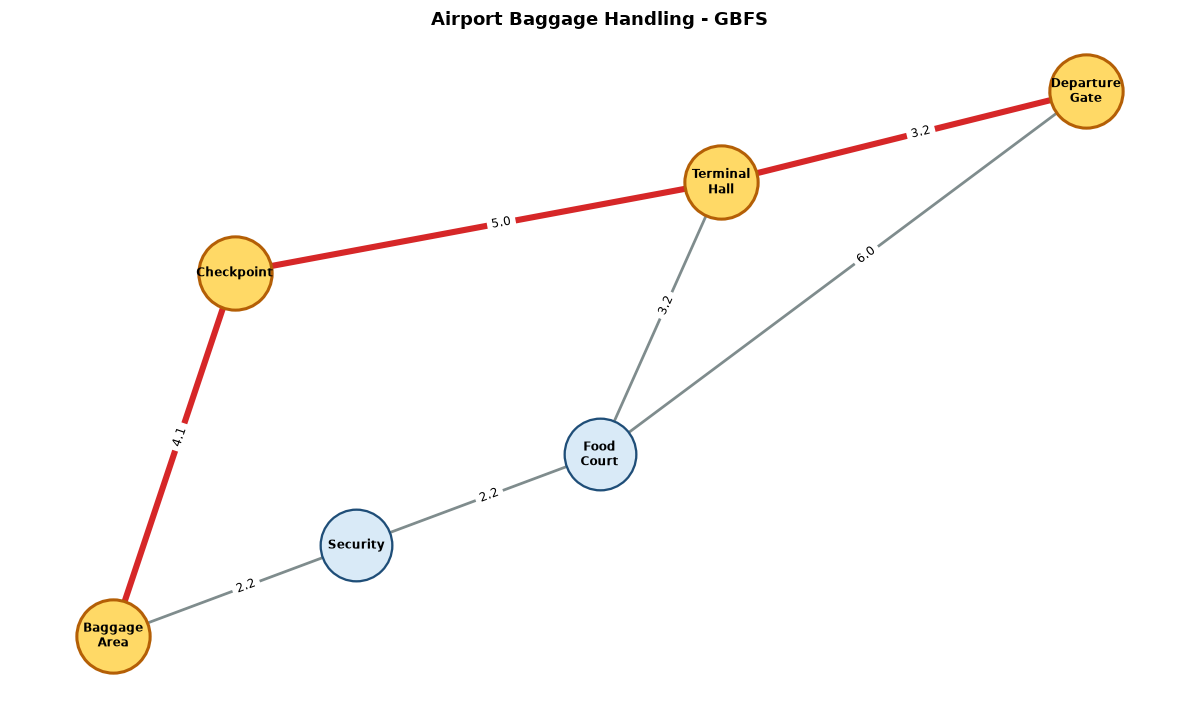

In [3]:
airport_locations = {
    "Baggage_Area": (0, 0),
    "Security": (2, 1),
    "Checkpoint": (1, 4),
    "Food_Court": (4, 2),
    "Terminal_Hall": (5, 5),
    "Departure_Gate": (8, 6),
}

airport_graph = {
    "Baggage_Area": {"Security": 2.2, "Checkpoint": 4.1},
    "Security": {"Food_Court": 2.2},
    "Checkpoint": {"Terminal_Hall": 5.0},
    "Food_Court": {"Terminal_Hall": 3.2, "Departure_Gate": 6.0},
    "Terminal_Hall": {"Departure_Gate": 3.2},
    "Departure_Gate": {},
}


def airport_heuristic(current, goal="Departure_Gate"):
    x1, y1 = airport_locations[current]
    x2, y2 = airport_locations[goal]
    return math.hypot(x2 - x1, y2 - y1)


def greedy_best_first_search(start, goal, graph):
    tie_breaker = count()
    frontier = [(airport_heuristic(start, goal), next(tie_breaker), start)]
    came_from = {start: None}
    visited = set()
    expansion_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        expansion_order.append(current)

        if current == goal:
            path = reconstruct_path(came_from, current)
            return path, calculate_path_cost(graph, path), expansion_order

        for neighbor in graph[current]:
            if neighbor not in visited and neighbor not in came_from:
                came_from[neighbor] = current
                heapq.heappush(
                    frontier,
                    (airport_heuristic(neighbor, goal), next(tie_breaker), neighbor),
                )
    return None, math.inf, expansion_order


airport_path, airport_cost, airport_expansion = greedy_best_first_search(
    "Baggage_Area", "Departure_Gate", airport_graph
)
print("GBFS")
print("Expansion order:", " -> ".join(airport_expansion))
print("Solution path:", " -> ".join(airport_path))
print(f"Total path cost: {airport_cost:.2f}")

plt.figure(figsize=(11, 6.5))
draw_weighted_graph(
    airport_graph,
    airport_locations,
    airport_path,
    "Airport Baggage Handling - GBFS",
    plt.gca(),
)
plt.tight_layout()
plt.show()

**How the heuristic guided GBFS.** From `Baggage_Area`, `Checkpoint` has the smaller straight-line distance to `Departure_Gate`, so GBFS expands it before `Security`. It then selects `Terminal_Hall` and reaches the goal. The resulting cost is 12.30; GBFS is fast and goal-directed, but it does not guarantee the lowest-cost path because it ignores the cost already travelled.

## Task 3: A* Search for an Emergency Supply Robot

A* uses `f(n) = g(n) + h(n)`, combining actual cost from the pharmacy with estimated remaining distance.

A* Search
Expansion order: Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward
Solution path: Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward
Total path cost: 10.40

A* selected-node information


,Node,g(n),h(n),f(n)
0,Pharmacy,0.0,10.00,10.00
1,Main_Corridor,2.2,7.81,10.01
2,Nursing_Station,4.4,5.66,10.06
3,Emergency_Ward,10.4,0.00,10.40


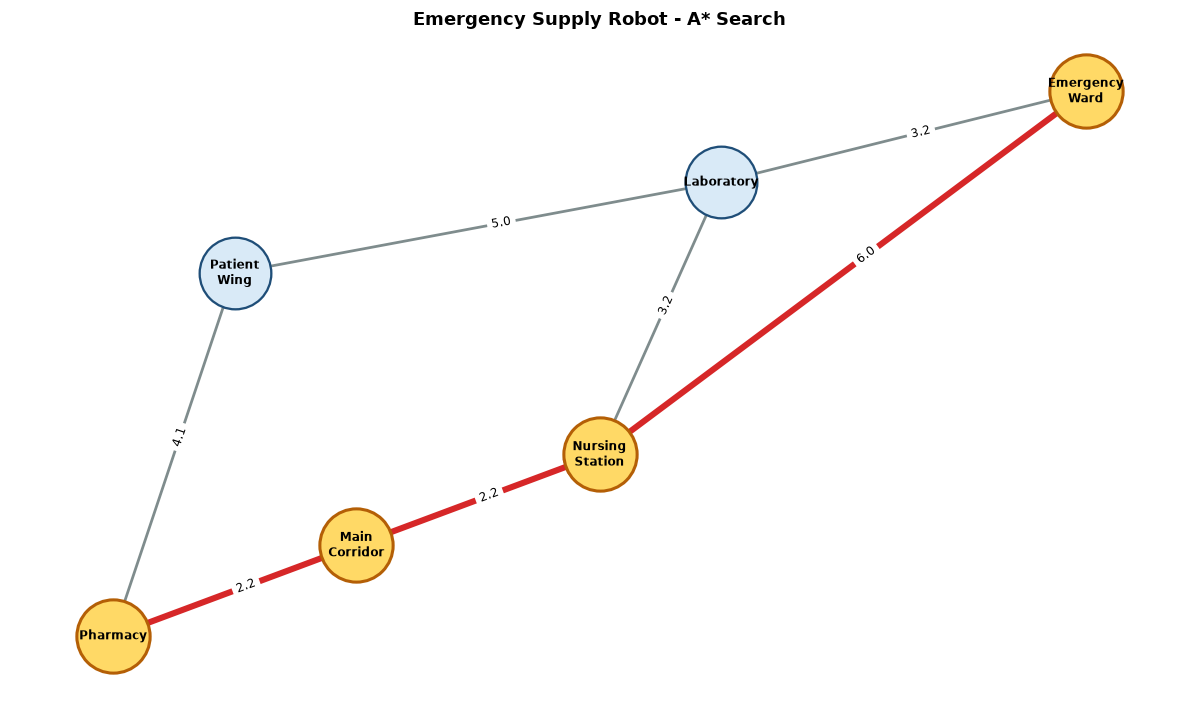

In [4]:
hospital_locations = {
    "Pharmacy": (0, 0),
    "Main_Corridor": (2, 1),
    "Patient_Wing": (1, 4),
    "Nursing_Station": (4, 2),
    "Laboratory": (5, 5),
    "Emergency_Ward": (8, 6),
}

hospital_graph = {
    "Pharmacy": {"Main_Corridor": 2.2, "Patient_Wing": 4.1},
    "Main_Corridor": {"Nursing_Station": 2.2},
    "Patient_Wing": {"Laboratory": 5.0},
    "Nursing_Station": {"Laboratory": 3.2, "Emergency_Ward": 6.0},
    "Laboratory": {"Emergency_Ward": 3.2},
    "Emergency_Ward": {},
}


def hospital_heuristic(current, goal="Emergency_Ward"):
    x1, y1 = hospital_locations[current]
    x2, y2 = hospital_locations[goal]
    return math.hypot(x2 - x1, y2 - y1)


def a_star_search(start, goal, graph):
    tie_breaker = count()
    frontier = [(hospital_heuristic(start, goal), next(tie_breaker), start)]
    came_from = {start: None}
    g_cost = {node: math.inf for node in graph}
    g_cost[start] = 0.0
    closed = set()
    expansion_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)
        if current in closed:
            continue
        closed.add(current)
        expansion_order.append(current)

        if current == goal:
            return (
                reconstruct_path(came_from, current),
                g_cost[current],
                expansion_order,
                g_cost,
            )

        for neighbor, edge_cost in graph[current].items():
            tentative_g = g_cost[current] + edge_cost
            if tentative_g < g_cost[neighbor]:
                came_from[neighbor] = current
                g_cost[neighbor] = tentative_g
                f_cost = tentative_g + hospital_heuristic(neighbor, goal)
                heapq.heappush(
                    frontier, (f_cost, next(tie_breaker), neighbor)
                )
                if neighbor in closed:
                    closed.remove(neighbor)

    return None, math.inf, expansion_order, g_cost


hospital_path, hospital_cost, hospital_expansion, hospital_g = a_star_search(
    "Pharmacy", "Emergency_Ward", hospital_graph
)
print("A* Search")
print("Expansion order:", " -> ".join(hospital_expansion))
print("Solution path:", " -> ".join(hospital_path))
print(f"Total path cost: {hospital_cost:.2f}")

node_information = pd.DataFrame(
    [
        {
            "Node": node,
            "g(n)": round(hospital_g[node], 2),
            "h(n)": round(hospital_heuristic(node), 2),
            "f(n)": round(hospital_g[node] + hospital_heuristic(node), 2),
        }
        for node in hospital_expansion
    ]
)
print("\nA* selected-node information")
display(node_information)

plt.figure(figsize=(11, 6.5))
draw_weighted_graph(
    hospital_graph,
    hospital_locations,
    hospital_path,
    "Emergency Supply Robot - A* Search",
    plt.gca(),
)
plt.tight_layout()
plt.show()

**A* compared with GBFS.** GBFS asks which node appears closest to the goal and ignores earlier travel. A* adds `g(n)`, so a node with an attractive heuristic can be delayed when reaching it has already been expensive. Here A* returns `Pharmacy -> Main_Corridor -> Nursing_Station -> Emergency_Ward` with cost 10.40.

**Required GUI.** The accompanying `app.py` lets the user select an initial node, goal node, and either GBFS or A*. It displays the selected algorithm, expansion order, solution path, total cost, and a NetworkX graph with the returned path highlighted.

## Task 4: Weighted A* for an Autonomous Delivery Drone

Weighted A* uses `f(n) = g(n) + w h(n)`. Larger `w` trusts the heuristic more strongly.

Heuristic values


,Node,h(n)
0,Distribution_Center,10.00
1,Zone_A,7.81
2,Zone_B,7.28
3,Zone_C,5.66
4,Zone_D,3.16
5,Customer_Building,0.00


Weighted A* comparison


,Weight w,Solution Path,Total Cost,Nodes Expanded,Expansion Order
0,1.0,Distribution_Center -> Zone_A -> Zone_C -> Customer_Building,10.4,5,Distribution_Center -> Zone_A -> Zone_C -> Zone_B -> Customer_Building
1,1.5,Distribution_Center -> Zone_A -> Zone_C -> Customer_Building,10.4,4,Distribution_Center -> Zone_A -> Zone_C -> Customer_Building
2,2.0,Distribution_Center -> Zone_B -> Zone_D -> Customer_Building,11.2,4,Distribution_Center -> Zone_B -> Zone_D -> Customer_Building
3,3.0,Distribution_Center -> Zone_B -> Zone_D -> Customer_Building,11.2,4,Distribution_Center -> Zone_B -> Zone_D -> Customer_Building


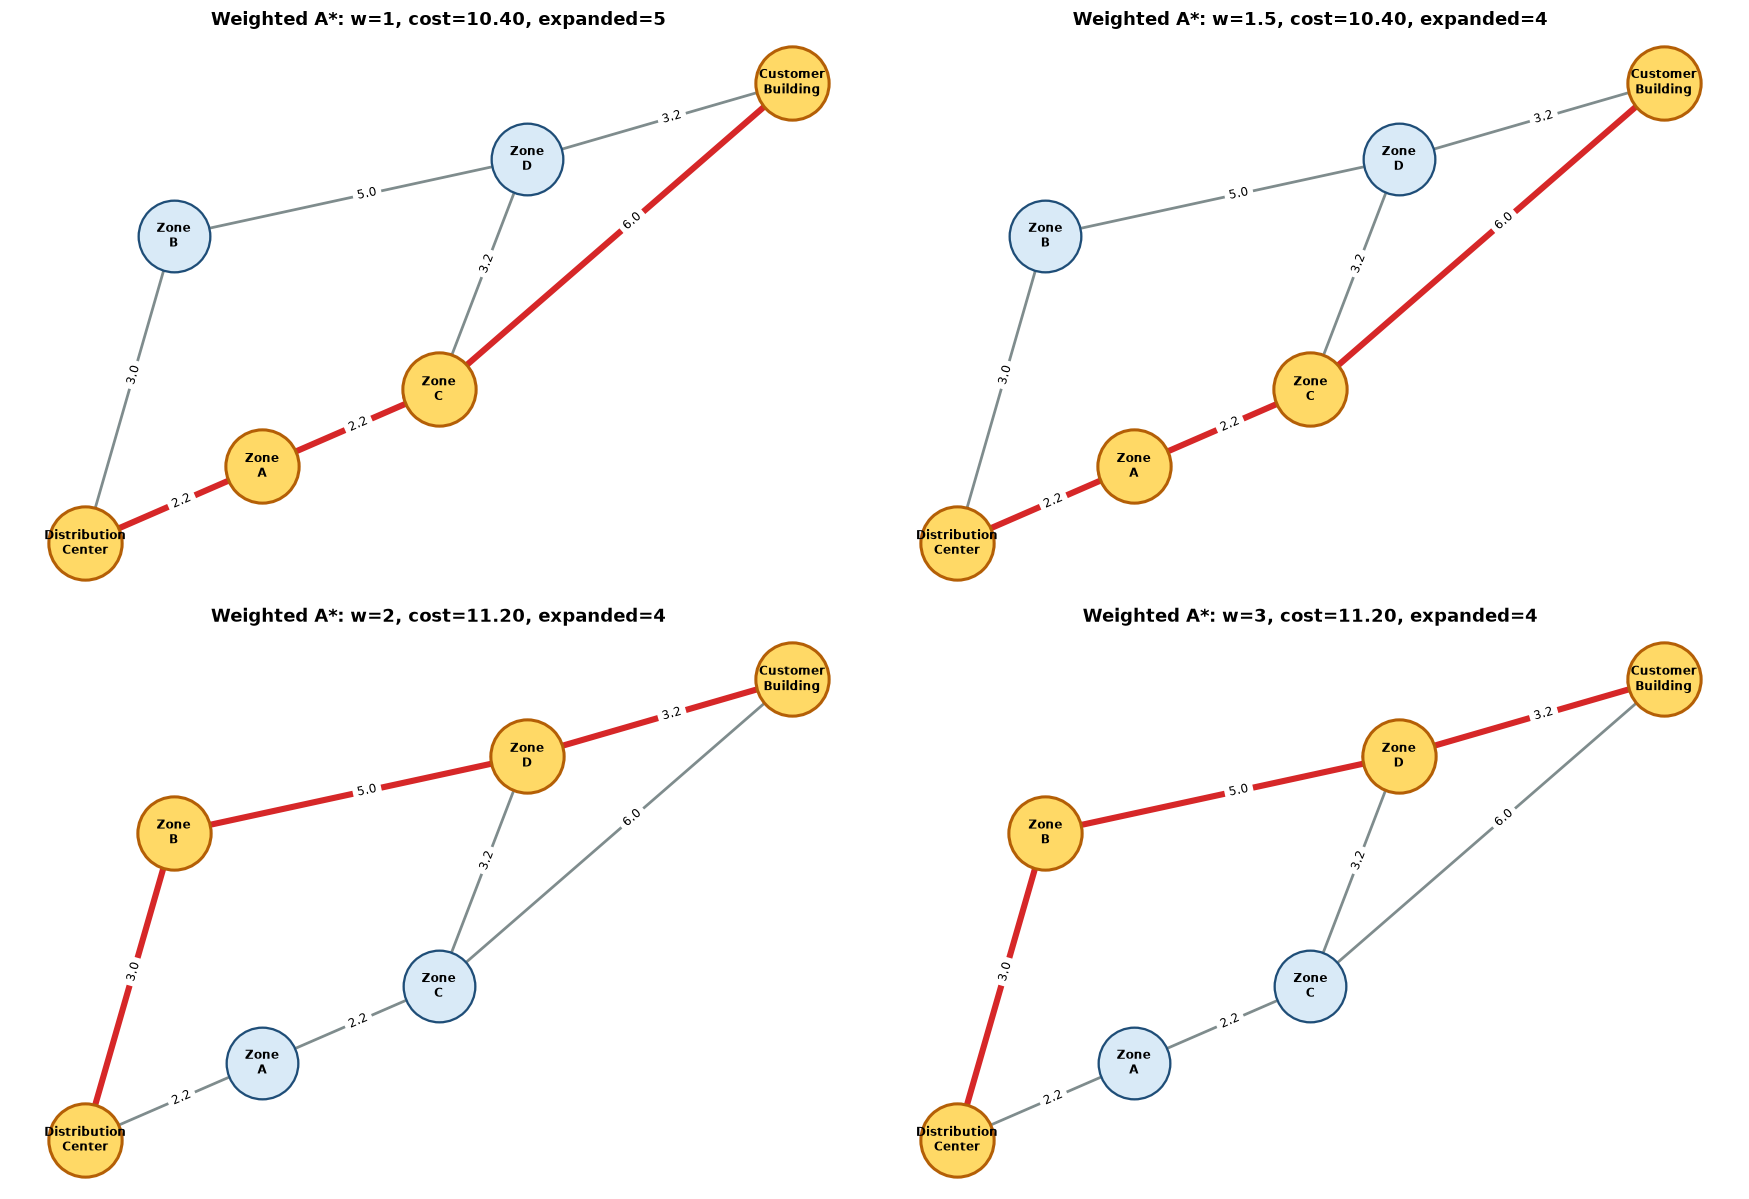

In [5]:
drone_locations = {
    "Distribution_Center": (0, 0),
    "Zone_A": (2, 1),
    "Zone_B": (1, 4),
    "Zone_C": (4, 2),
    "Zone_D": (5, 5),
    "Customer_Building": (8, 6),
}

drone_graph = {
    "Distribution_Center": {"Zone_A": 2.2, "Zone_B": 3.0},
    "Zone_A": {"Zone_C": 2.2},
    "Zone_B": {"Zone_D": 5.0},
    "Zone_C": {"Zone_D": 3.2, "Customer_Building": 6.0},
    "Zone_D": {"Customer_Building": 3.2},
    "Customer_Building": {},
}


def drone_heuristic(node, goal="Customer_Building"):
    x1, y1 = drone_locations[node]
    x2, y2 = drone_locations[goal]
    return math.hypot(x2 - x1, y2 - y1)


def weighted_a_star(start, goal, graph, weight):
    tie_breaker = count()
    frontier = [(weight * drone_heuristic(start, goal), next(tie_breaker), start)]
    came_from = {start: None}
    g_cost = {node: math.inf for node in graph}
    g_cost[start] = 0.0
    closed = set()
    expansion_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)
        if current in closed:
            continue
        closed.add(current)
        expansion_order.append(current)

        if current == goal:
            return (
                reconstruct_path(came_from, current),
                g_cost[current],
                expansion_order,
            )

        for neighbor, edge_cost in graph[current].items():
            tentative_g = g_cost[current] + edge_cost
            if tentative_g < g_cost[neighbor]:
                came_from[neighbor] = current
                g_cost[neighbor] = tentative_g
                f_cost = tentative_g + weight * drone_heuristic(neighbor, goal)
                heapq.heappush(
                    frontier, (f_cost, next(tie_breaker), neighbor)
                )
                if neighbor in closed:
                    closed.remove(neighbor)

    return None, math.inf, expansion_order


print("Heuristic values")
display(
    pd.DataFrame(
        {
            "Node": list(drone_locations),
            "h(n)": [round(drone_heuristic(node), 2) for node in drone_locations],
        }
    )
)

weights = [1, 1.5, 2, 3]
drone_results = []
for weight in weights:
    path, cost_value, expansion_order = weighted_a_star(
        "Distribution_Center", "Customer_Building", drone_graph, weight
    )
    drone_results.append(
        {
            "Weight w": weight,
            "Solution Path": " -> ".join(path),
            "Total Cost": round(cost_value, 2),
            "Nodes Expanded": len(expansion_order),
            "Expansion Order": " -> ".join(expansion_order),
        }
    )

results_df = pd.DataFrame(drone_results)
print("Weighted A* comparison")
display(results_df)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
for ax, weight in zip(axes.flat, weights):
    path, cost_value, expansion_order = weighted_a_star(
        "Distribution_Center", "Customer_Building", drone_graph, weight
    )
    draw_weighted_graph(
        drone_graph,
        drone_locations,
        path,
        f"Weighted A*: w={weight}, cost={cost_value:.2f}, expanded={len(expansion_order)}",
        ax,
    )
plt.tight_layout()
plt.show()

**Comparison.** At `w=1`, Weighted A* is normal A* and balances actual and estimated cost. At `w=1.5`, the same optimal route is found with fewer expansions. At `w=2` and `w=3`, the heuristic dominates enough to select the visually promising `Zone_B -> Zone_D` branch; only four nodes are expanded, but the returned cost rises from 10.40 to 11.20. Thus larger weights can reduce search effort while losing the optimality guarantee for `w > 1`.

## Task 5: Finding a Charging Station Using Multiple Goals

The heuristic is the minimum Euclidean distance from the current node to any charging station. Each algorithm stops when it removes a charging station from its frontier.

GBFS and A* comparison


,Measure,GBFS,A*
0,Charging station reached,Charging_Central,Charging_Central
1,Solution path,Current_Location -> Junction_A -> Junction_C -> Charging_Central,Current_Location -> Junction_A -> Junction_C -> Charging_Central
2,Total path cost,8.40,8.40
3,Number of nodes expanded,4,4
4,Expansion order,Current_Location -> Junction_A -> Junction_C -> Charging_Central,Current_Location -> Junction_A -> Junction_C -> Charging_Central


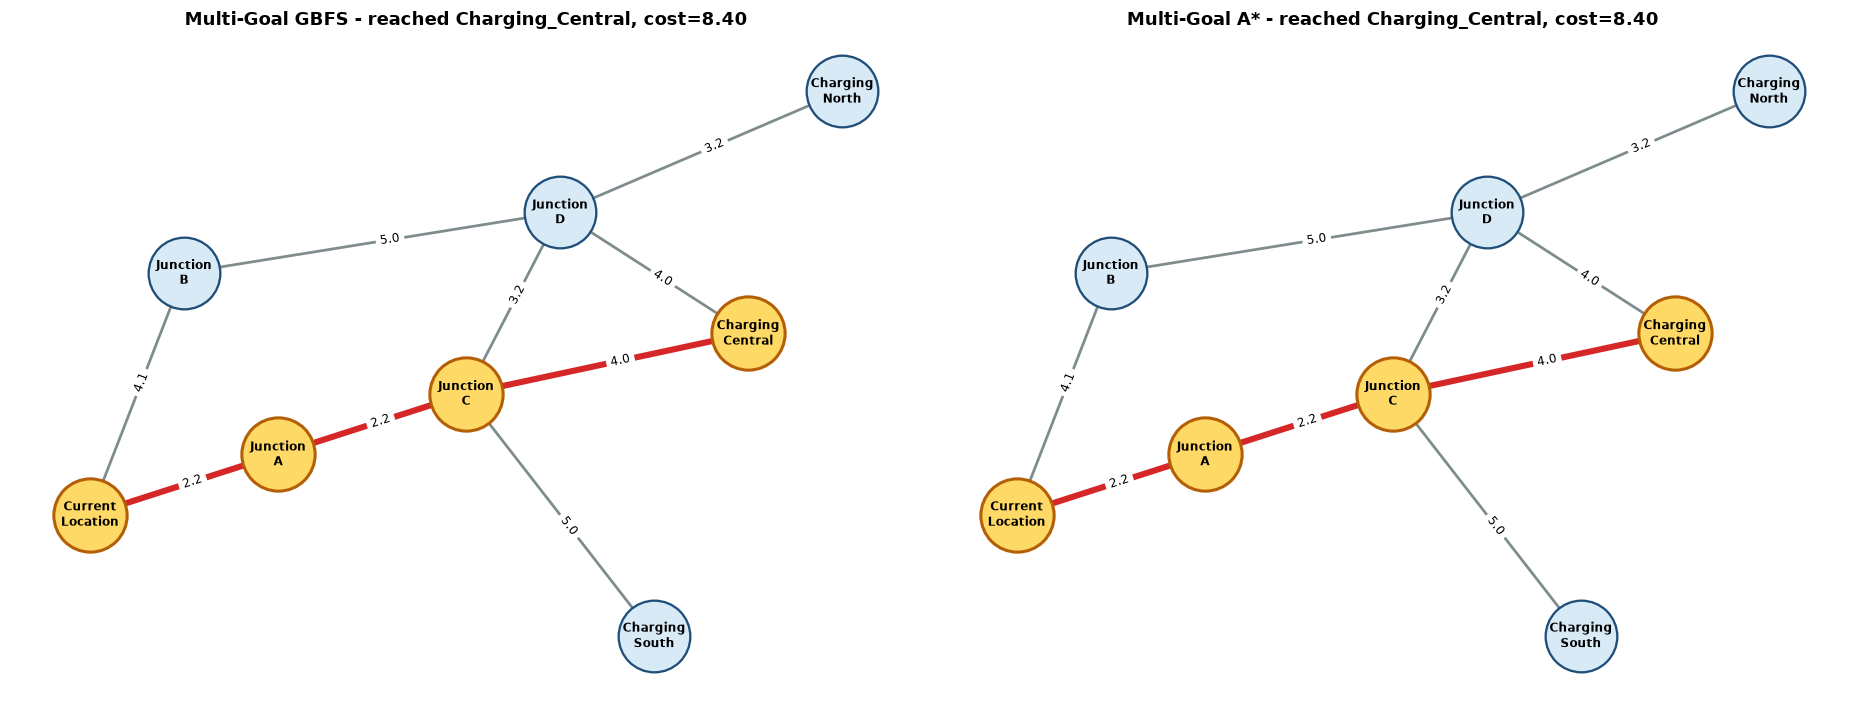

In [6]:
charging_locations = {
    "Current_Location": (0, 0),
    "Junction_A": (2, 1),
    "Junction_B": (1, 4),
    "Junction_C": (4, 2),
    "Junction_D": (5, 5),
    "Charging_North": (8, 7),
    "Charging_Central": (7, 3),
    "Charging_South": (6, -2),
}

charging_graph = {
    "Current_Location": {"Junction_A": 2.2, "Junction_B": 4.1},
    "Junction_A": {"Junction_C": 2.2},
    "Junction_B": {"Junction_D": 5.0},
    "Junction_C": {
        "Junction_D": 3.2,
        "Charging_Central": 4.0,
        "Charging_South": 5.0,
    },
    "Junction_D": {"Charging_North": 3.2, "Charging_Central": 4.0},
    "Charging_North": {},
    "Charging_Central": {},
    "Charging_South": {},
}

charging_goals = {
    "Charging_North",
    "Charging_Central",
    "Charging_South",
}


def nearest_station_heuristic(node):
    x1, y1 = charging_locations[node]
    return min(
        math.hypot(charging_locations[goal][0] - x1, charging_locations[goal][1] - y1)
        for goal in charging_goals
    )


def multi_goal_gbfs(start, graph, goals):
    tie_breaker = count()
    frontier = [(nearest_station_heuristic(start), next(tie_breaker), start)]
    came_from = {start: None}
    visited = set()
    expansion_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)
        if current in visited:
            continue
        visited.add(current)
        expansion_order.append(current)

        if current in goals:
            path = reconstruct_path(came_from, current)
            return path, calculate_path_cost(graph, path), expansion_order, current

        for neighbor in graph[current]:
            if neighbor not in visited and neighbor not in came_from:
                came_from[neighbor] = current
                heapq.heappush(
                    frontier,
                    (nearest_station_heuristic(neighbor), next(tie_breaker), neighbor),
                )
    return None, math.inf, expansion_order, None


def multi_goal_a_star(start, graph, goals):
    tie_breaker = count()
    frontier = [(nearest_station_heuristic(start), next(tie_breaker), start)]
    came_from = {start: None}
    g_cost = {node: math.inf for node in graph}
    g_cost[start] = 0.0
    closed = set()
    expansion_order = []

    while frontier:
        _, _, current = heapq.heappop(frontier)
        if current in closed:
            continue
        closed.add(current)
        expansion_order.append(current)

        if current in goals:
            return (
                reconstruct_path(came_from, current),
                g_cost[current],
                expansion_order,
                current,
            )

        for neighbor, edge_cost in graph[current].items():
            tentative_g = g_cost[current] + edge_cost
            if tentative_g < g_cost[neighbor]:
                came_from[neighbor] = current
                g_cost[neighbor] = tentative_g
                heapq.heappush(
                    frontier,
                    (
                        tentative_g + nearest_station_heuristic(neighbor),
                        next(tie_breaker),
                        neighbor,
                    ),
                )
                if neighbor in closed:
                    closed.remove(neighbor)
    return None, math.inf, expansion_order, None


gbfs_path, gbfs_cost, gbfs_expansion, gbfs_goal = multi_goal_gbfs(
    "Current_Location", charging_graph, charging_goals
)
astar_path, astar_cost, astar_expansion, astar_goal = multi_goal_a_star(
    "Current_Location", charging_graph, charging_goals
)

comparison = pd.DataFrame(
    {
        "Measure": [
            "Charging station reached",
            "Solution path",
            "Total path cost",
            "Number of nodes expanded",
            "Expansion order",
        ],
        "GBFS": [
            gbfs_goal,
            " -> ".join(gbfs_path),
            f"{gbfs_cost:.2f}",
            len(gbfs_expansion),
            " -> ".join(gbfs_expansion),
        ],
        "A*": [
            astar_goal,
            " -> ".join(astar_path),
            f"{astar_cost:.2f}",
            len(astar_expansion),
            " -> ".join(astar_expansion),
        ],
    }
)
print("GBFS and A* comparison")
display(comparison)

fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
draw_weighted_graph(
    charging_graph,
    charging_locations,
    gbfs_path,
    f"Multi-Goal GBFS - reached {gbfs_goal}, cost={gbfs_cost:.2f}",
    axes[0],
)
draw_weighted_graph(
    charging_graph,
    charging_locations,
    astar_path,
    f"Multi-Goal A* - reached {astar_goal}, cost={astar_cost:.2f}",
    axes[1],
)
plt.tight_layout()
plt.show()

**Analysis.** Both algorithms reach `Charging_Central` through `Junction_A -> Junction_C` with cost 8.40 and expand four nodes in this particular graph. They can make different decisions in other graphs because GBFS ranks nodes using only the nearest-station estimate, while A* also includes the accumulated route cost. A* can therefore reject a node that looks close to a station when reaching that node has already been expensive.

## Submission reminder

1. Keep all notebook outputs visible; do not clear them.
2. Upload this `.ipynb` file to GCR.
3. Push the accompanying Streamlit project to GitHub and submit the repository link.
4. Deploy `app.py` on Streamlit Community Cloud and submit the deployed app link.